# Kelmarsh wind farm: what the data looks like

Six Senvion MM92 turbines (2,050 kW) in the UK, one row every 10 minutes per turbine. This notebook looks at **2019 only**: 2020 is the test year, so it stays unseen until the models are final. It reads the compact files made by `prepare_data.py`.

**Sections:** 1. Raw files · 1b. How the datasets connect · 2. Data quality · 3. Wind and production · 4. Power curve · 5. Status log · 6. Do the turbines agree? · 7. Nacelle wind vs. weather data · 8. Does choosing the day matter? · 9. Browse samples

To browse the data yourself, go to section 9, change the arguments and re-run the cell.

## What we learned (2019)

1. **The data is clean and ready to use.** Power is missing in about 0.13% of rows, the longest gap is 6 hours, and 97% of rows count as healthy.
2. **The turbines behave almost identically once you account for their own wind.** Yearly energy differs by 37% between turbines, but at 9 m/s they all produce 69–71% of rated. The differences come from wind, not from the machines.
3. **There are no obvious natural faults to learn from.** Only 0.18% of healthy rows fall far below normal, and they're scattered. This confirms that M2 needs injected faults.
4. **Weather-model wind is a much weaker input than nacelle wind:** 7.8% vs. 1.8% of rated hourly error. This backs the decision to give M4 its own model.
5. **Choosing the day saves energy, but the size depends on the job.** With perfect weather knowledge, a job with no waiting loss saves about 3.9 MWh on average. A fault losing 1.4 MWh/day saves about 1.6 on average and nothing in the median case. The design doc's 19.4 vs. 7.6 MWh example is close to the most extreme case here, not a typical one.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA = Path("../data/kelmarsh") if Path("../data/kelmarsh").exists() else Path("data/kelmarsh")
RATED = 2050.0

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
TURBINE_COLOR = dict(zip(["KWF1", "KWF2", "KWF3", "KWF4", "KWF5", "KWF6"], [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]))
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.titlelocation": "left", "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0, "font.size": 10, "figure.dpi": 110, "legend.frameon": False})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)

## 1. Raw files

Each annual zip has a data file and a status file per turbine. This is exactly what they contain, before any cleaning.

**Inside each annual zip** (this preview is static text, since the zip is deleted after `prepare_data.py` runs):

```text
  147.3 MB  Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv
    0.7 MB  Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv
  150.5 MB  Turbine_Data_Kelmarsh_2_2019-01-01_-_2020-01-01_229.csv
    0.7 MB  Status_Kelmarsh_2_2019-01-01_-_2020-01-01_229.csv
... 12 files in total
# This file was exported by Greenbyte at 2022-01-27 16:28:33. Please see https://www.greenbyte.com for more in
#
# Turbine: Kelmarsh 1
# Turbine type: Senvion MM92
# Time zone: UTC
# Time interval: 2019-01-01 00:00:00 - 2020-01-01 00:00:00 (365 days)
#
# Data that is missing or is erroneous has been marked with the value "NaN"
#

299 columns. Many are the same signal as Max, Min and StdDev:
195 distinct signals. Examples: Current L3 / W, Energy Export counter (kWh), Energy Import counter (kWh), Power, Reactive Energy Import (kvarh), Time-based Contractual Avail., Wind direction, Energy Budget - Default (kWh), Gear oil inlet pressure, Current L2 / V (A), Energy Theoretical (kWh), Blade angle (pitch position) A
```

```text
Turbine 1, random raw rows (a few of the 299 columns):
          # Date and time  Wind speed (m/s)  Wind speed, Standard deviation (m/s)  Wind direction (°)  Power (kW)  Rotor speed (RPM)  Blade angle (pitch position) A (°)  \
81    2019-01-01 13:30:00              6.08                                  1.08              312.12      475.12              11.28                                0.00   
263   2019-01-02 19:50:00              2.87                                  0.51              357.27       -2.43               0.69                               44.99   
339   2019-01-03 08:30:00              1.27                                  0.24              322.68       -1.08               0.03                               44.99   
805   2019-01-06 14:10:00              7.08                                  0.78              295.57      809.44              13.39                                0.00   
933   2019-01-07 11:30:00             10.12                                  1.06              259.68     1888.36              15.17                                1.87   
1338  2019-01-10 07:00:00              3.51                                  0.65              312.06       84.94               8.18                                0.49   
1459  2019-01-11 03:10:00              3.96                                  0.96              314.66      138.28               8.42                                0.13   
1802  2019-01-13 12:20:00              9.90                                  0.80              251.17     1848.66              15.15                                0.66   

      Nacelle ambient temperature (°C)  Gear oil temperature (°C)  
81                               10.84                      56.47  
263                               4.70                      38.52  
339                               3.70                      20.68  
805                               9.27                      55.44  
933                               8.91                      50.13  
1338                              2.74                      52.86  
1459                              7.03                      55.24  
1802                              8.76                      51.42  
```

In [2]:
TURBINES, EVENTS, FACTS, WX = (DATA / f for f in ("turbines_2019.parquet", "events_2019.parquet", "Kelmarsh_WT_static.csv", "weather_2019.parquet"))
if not TURBINES.exists():
    raise SystemExit("Data not found. From the project root, run: python prepare_data.py")
df = pd.read_parquet(TURBINES)
# Stored compactly as 32-bit numbers; back to 64-bit so printed values stay clean.
df[df.select_dtypes("float32").columns] = df.select_dtypes("float32").astype(float).round(4)
events = pd.read_parquet(EVENTS)
VALUE_COLUMNS = [c for c in df.columns if c not in ("ts", "turbine", "healthy")]
df["frac"] = df["power_kw"] / RATED
print(f"{len(df):,} rows, {df.turbine.nunique()} turbines, {df.ts.min()} to {df.ts.max()}; {len(events):,} status events")
print(f"Healthy rows: {df.healthy.mean():.1%}")

315,360 rows, 6 turbines, 2019-01-01 00:00:00 to 2019-12-31 23:50:00; 59,326 status events
Healthy rows: 97.0%


In [3]:
print("Status log for turbine 1, random events:")
display(events[events.turbine == "KWF1"].sample(10, random_state=4).sort_values("start")[["start", "end", "Status", "Code", "Message", "IEC category"]])

Status log for turbine 1, random events:


,start,end,Status,Code,Message,IEC category
373,2019-01-30 17:18:08,2019-01-30 17:18:55,Informational,10,Wind < start wind,Out of Environmental Specification
862,2019-03-18 15:52:11,NaT,Informational,100130,Automatic start-up,Full Performance
907,2019-03-21 11:56:08,NaT,Informational,100070,Brake program 50,Out of Environmental Specification
2632,2019-05-23 20:36:31,NaT,Informational,0,System OK,Full Performance
3403,2019-06-22 05:15:49,NaT,Informational,100210,Mains operation,Full Performance
3571,2019-06-28 06:27:17,NaT,Informational,100180,Run-up,Technical Standby
3726,2019-07-03 12:17:58,NaT,Informational,100210,Mains operation,Full Performance
3795,2019-07-03 15:46:19,NaT,Informational,100210,Mains operation,Full Performance
5902,2019-09-01 21:34:20,NaT,Informational,0,System OK,Full Performance
6700,2019-10-04 16:15:17,NaT,Informational,100200,Mains run-up,Full Performance


## 1b. How the datasets connect

**Four sources, not two.** The first three come from the wind farm. The fourth comes from a weather service, not from the farm.

| Source | What one row is | How often | How many | Where it comes from |
|---|---|---|---|---|
| **Turbine data** | One turbine over 10 minutes: power, wind, temperatures... | Every 10 min | 52,560 rows × 6 turbines | Sensors on each turbine |
| **Status log** | One event, such as a stop or a warning | Whenever it happens | 59,326 events | The turbine's controller |
| **Turbine facts** | One turbine: rating, hub height, location | Fixed | 6 rows | The operator |
| **Weather** | The whole site for one hour | Hourly | 8,760 rows | Open-Meteo, a weather model |

They connect on **turbine** and **time**. The cells below follow one moment through all four.

In [4]:
wx = pd.read_parquet(WX)
wx = wx.assign(hour=wx.ts_utc.dt.tz_localize(None)).set_index("hour").drop(columns="ts_utc")
facts = pd.read_csv(FACTS, encoding="utf-8-sig")
MOMENT = pd.Timestamp("2019-03-16 12:00")   # Change this to follow any other moment in 2019.

print("TURBINE FACTS: fixed values, one row per turbine")
display(facts[["Alternative Title", "Model", "Rated power (kW)", "Hub Height (m)", "Rotor Diameter (m)", "Latitude", "Longitude"]])
print(f"TURBINE DATA at {MOMENT}: one row per turbine, for the 10 minutes starting then")
display(df[df.ts == MOMENT][["ts", "turbine", "power_kw", "frac", "wind_ms", "wind_dir_deg", "temp_c", "rotor_rpm", "pitch_deg", "healthy"]].round(2))
print(f"WEATHER for that hour: one row for the whole site")
display(wx.loc[[MOMENT.floor("h")]].round(2))
near = events[(events.start >= MOMENT - pd.Timedelta(hours=12)) & (events.start <= MOMENT + pd.Timedelta(hours=12))]
print(f"STATUS LOG within 12 hours of it: {len(near)} events")
display(near.sort_values("start")[["turbine", "start", "end", "Status", "Message", "IEC category"]].head(8))

TURBINE FACTS: fixed values, one row per turbine


,Alternative Title,Model,Rated power (kW),Hub Height (m),Rotor Diameter (m),Latitude,Longitude
0,KWF1,MM92,2050,78.5,92,52.400604,-0.947133
1,KWF2,MM92,2050,78.5,92,52.402551,-0.949527
2,KWF3,MM92,2050,68.5,92,52.403834,-0.944190
3,KWF4,MM92,2050,78.5,92,52.398781,-0.941150
4,KWF5,MM92,2050,78.5,92,52.402308,-0.940537
5,KWF6,MM92,2050,68.5,92,52.400687,-0.936093


TURBINE DATA at 2019-03-16 12:00:00: one row per turbine, for the 10 minutes starting then


,ts,turbine,power_kw,frac,wind_ms,wind_dir_deg,temp_c,rotor_rpm,pitch_deg,healthy
10728,2019-03-16 12:00:00,KWF1,2050.01,1.00,18.40,227.48,11.50,15.18,17.11,True
63288,2019-03-16 12:00:00,KWF2,1456.24,0.71,15.75,226.33,11.31,12.28,25.37,False
115848,2019-03-16 12:00:00,KWF3,2060.00,1.00,18.24,227.99,11.00,15.21,17.18,True
168408,2019-03-16 12:00:00,KWF4,2036.86,0.99,15.68,227.43,11.31,15.19,13.38,True
220968,2019-03-16 12:00:00,KWF5,2056.02,1.00,17.77,223.13,10.62,15.23,16.35,True
273528,2019-03-16 12:00:00,KWF6,2030.36,0.99,13.45,226.85,11.82,15.20,10.86,True


WEATHER for that hour: one row for the whole site


,wind_speed_100m,wind_gusts_10m,precipitation,relative_humidity_2m,temperature_2m,surface_pressure
hour,,,,,,
2019-03-16 12:00:00,20.34,25.5,0.0,71,10.9,980.6


STATUS LOG within 12 hours of it: 109 events


,turbine,start,end,Status,Message,IEC category
8548,KWF2,2019-03-16 08:39:02,NaT,Informational,Brake program 52,Full Performance
8547,KWF2,2019-03-16 08:39:02,2019-03-16 08:54:40,Stop,Tower oscillation X level 2,Forced outage
28336,KWF4,2019-03-16 08:46:43,2019-03-16 09:02:22,Stop,Tower oscillation X level 2,Forced outage
28337,KWF4,2019-03-16 08:46:43,NaT,Informational,Brake program 52,Full Performance
8550,KWF2,2019-03-16 08:54:40,NaT,Informational,Automatic start-up,Full Performance
8549,KWF2,2019-03-16 08:54:40,NaT,Informational,System OK,Full Performance
8551,KWF2,2019-03-16 08:56:40,NaT,Informational,Run-up,Technical Standby
8552,KWF2,2019-03-16 08:58:34,NaT,Informational,Mains connection,Full Performance


**The same day from the turbines and from the weather model.** The turbines report every 10 minutes and the weather every hour, so the weather is much smoother. Change `DAY` to see any other day.

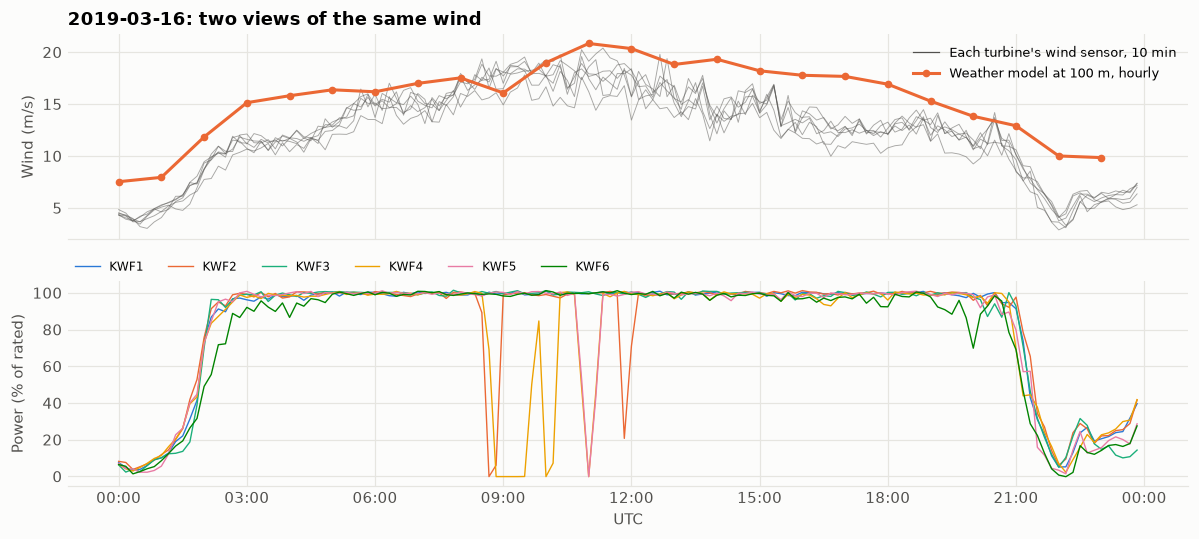

In [5]:
DAY = "2019-03-16"
t0 = pd.Timestamp(DAY); t1 = t0 + pd.Timedelta(days=1)
g = df[(df.ts >= t0) & (df.ts < t1)]
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for t, x in g.groupby("turbine"):
    axes[0].plot(x.ts, x.wind_ms, color=MUTED, linewidth=0.6, alpha=0.5)
axes[0].plot([], [], color=MUTED, linewidth=0.8, label="Each turbine's wind sensor, 10 min")
day_wx = wx[(wx.index >= t0) & (wx.index < t1)]
axes[0].plot(day_wx.index, day_wx.wind_speed_100m, color=ORANGE, linewidth=2, marker="o", markersize=4, label="Weather model at 100 m, hourly")
axes[0].set_ylabel("Wind (m/s)"); axes[0].legend(fontsize=8.5); axes[0].set_title(f"{DAY}: two views of the same wind")
for t, x in g.groupby("turbine"):
    axes[1].plot(x.ts, x.frac * 100, color=TURBINE_COLOR[t], linewidth=0.9, label=t)
axes[1].set_ylabel("Power (% of rated)"); axes[1].legend(ncol=6, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); axes[1].set_xlabel("UTC")
plt.tight_layout(); plt.show()

**Joining them.** This is the step that makes the data usable together. Each 10-minute row looks up the hour it falls in, so every row of that hour gets the same weather values, and the turbine facts come from a lookup on the turbine.

In [6]:
facts_short = facts.assign(turbine=facts["Alternative Title"])[["turbine", "Hub Height (m)"]]
joined = df.assign(hour=df.ts.dt.floor("h")).merge(wx.reset_index(), on="hour", how="left").merge(facts_short, on="turbine", how="left")
print(f"Rows before and after joining: {len(df):,} and {len(joined):,}. Rows with no weather match: {joined.surface_pressure.isna().sum():,}")
joined["air_density"] = joined.surface_pressure * 100 / (287.05 * (joined.temp_c + 273.15))
one = joined[(joined.ts >= MOMENT) & (joined.ts < MOMENT + pd.Timedelta(minutes=30)) & (joined.turbine == "KWF2")]
print("\nOne turbine, three rows after joining:")
display(one[["ts", "turbine", "Hub Height (m)", "power_kw", "wind_ms", "temp_c", "surface_pressure", "air_density", "relative_humidity_2m", "wind_speed_100m"]].round(3))

print("Do the two sources agree on time? Correlation of hourly wind, shifting the weather by some hours:")
nac = df[df.healthy].assign(hour=lambda x: x.ts.dt.floor("h")).groupby("hour").wind_ms.median()
print({f"{k:+d}h": round(float(nac.corr(wx.wind_speed_100m.shift(k))), 3) for k in (-2, -1, 0, 1, 2)})
# Turbine rows average across an hour, but weather values are spot readings at the start of the hour. Averaging two readings matches them.
mid = (wx.wind_speed_100m + wx.wind_speed_100m.shift(-1)) / 2
print(f"Using the average of the readings at the start and end of each hour: {nac.corr(mid):.3f}")
tn = df.assign(hour=df.ts.dt.floor("h")).groupby("hour").temp_c.median()
d_temp = (tn - wx.temperature_2m).dropna()
print(f"\nTurbine temperature sensor minus weather model: mean {d_temp.mean():+.1f} C, typical difference {d_temp.abs().mean():.1f} C, correlation {tn.corr(wx.temperature_2m):.3f}")
print(f"Air density across the year: {joined.air_density.quantile(.01):.3f} to {joined.air_density.quantile(.99):.3f} kg/m3, a {joined.air_density.quantile(.99) / joined.air_density.quantile(.01) - 1:.0%} swing")
hi = joined[joined.healthy & joined.wind_ms.between(6.75, 7.25)]
q = hi.groupby(pd.qcut(hi.air_density, 4, labels=["thinnest air", "", " ", "densest air"]), observed=True).frac.median() * 100
print(f"Does it matter? Median power at 7 m/s: {q.iloc[0]:.1f}% of rated in the thinnest quarter of air, {q.iloc[-1]:.1f}% in the densest")

Rows before and after joining: 315,360 and 315,360. Rows with no weather match: 0

One turbine, three rows after joining:


,ts,turbine,Hub Height (m),power_kw,wind_ms,temp_c,surface_pressure,air_density,relative_humidity_2m,wind_speed_100m
63288,2019-03-16 12:00:00,KWF2,78.5,1456.238,15.748,11.310,980.6,1.201,71,20.34
63289,2019-03-16 12:10:00,KWF2,78.5,2048.074,18.147,11.225,980.6,1.201,71,20.34
63290,2019-03-16 12:20:00,KWF2,78.5,2014.033,16.890,11.320,980.6,1.201,71,20.34


Do the two sources agree on time? Correlation of hourly wind, shifting the weather by some hours:


{'-2h': 0.896, '-1h': 0.919, '+0h': 0.915, '+1h': 0.887, '+2h': 0.849}
Using the average of the readings at the start and end of each hour: 0.925



Turbine temperature sensor minus weather model: mean +1.6 C, typical difference 1.7 C, correlation 0.967
Air density across the year: 1.160 to 1.282 kg/m3, a 11% swing
Does it matter? Median power at 7 m/s: 33.7% of rated in the thinnest quarter of air, 35.4% in the densest


**What was in the 299 turbine columns?** This grouping was made from the original files, before the unused columns were dropped.

```text
                                                                 group  columns  of which Max/Min/Std copies                                                               examples
0  Vendor calculations: lost production, availability, potential power       54                            0  Lost Production (Contractual) (kWh), Lost Production (Time-based I...
1                                                      Energy counters       13                            0  Energy Export (kWh), Energy Export counter (kWh), Energy Import (kWh)
2                                  Electrical: voltage, current, power       56                           36        Power (kW), Power, Standard deviation (kW), Power, Minimum (kW)
3                                                         Temperatures       72                           51  Front bearing temperature (°C), Rear bearing temperature (°C), Sta...
4                                                                 Wind       18                           12  Wind speed (m/s), Wind speed, Standard deviation (m/s), Wind speed...
5                                 Motion: rotor, generator, pitch, yaw       48                           36  Nacelle position (°), Nacelle position, Standard deviation (°), Na...
6                                              Oil, pressure and other       38                           21     # Date and time, Vane position 1+2 (°), Vane position 1+2, Max (°)
prepare_data.py keeps 13 of the 299 columns.
```

### How each piece gets used

| Dataset | Field | Used for | In which model |
|---|---|---|---|
| Turbine data | `power_kw` | What the model learns to predict, and the real output to compare against | M1, M2 |
| Turbine data | `wind_ms`, `wind_std_ms`, `wind_dir_deg`, `temp_c` | Inputs: conditions at the turbine right now | M1 |
| Turbine data | Vendor columns (`Potential power`, `Lost Production`) | **Filtering and cross-checks only.** As inputs they would leak the vendor's own answer | Cleaning |
| Status log | `Status`, `IEC category` | Removes stops, so the model doesn't learn a fault as normal | Cleaning, M1, M2 |
| Status log | Stop messages, `Scheduled Maintenance` | Reality check on how long jobs take | Optimizer |
| Turbine facts | `Rated power` | Turns kW into a share of rated, so the model transfers to other turbine sizes | All |
| Turbine facts | `Hub Height` | Adjusts weather wind to each turbine's height | M4 |
| Weather | `surface_pressure` | With temperature, gives air density, an M1 input | M1 |
| Weather | `relative_humidity_2m` | Tells when icing is possible | M2 |
| Weather | `wind_speed_*` | The future: a forecast is all we have for tomorrow | M4 |
| Weather | gusts, `precipitation` | Whether a crew can safely work | M4, Optimizer |

**The key idea:** the **turbine data describes now and the past**, so it can tell us whether a turbine is underperforming today (M1, M2). It can't say anything about tomorrow. **Only the weather reaches the future**, so it's what tells us what stopping would cost on each coming day (M4). The 2019 weather archive stands in for a forecast while we train, because it can be lined up with what the turbines really produced.


**What this shows**

- **One moment isn't uniform:** at 12:00 on 16 March, the six wind sensors read 13.5 to 18.4 m/s while the weather model says 20.3 m/s for the whole site. That's why turbines are compared with their *own* wind. KWF2 is also flagged abnormal in that row, because it was restarting after a stop that morning, which the status log explains.
- **The sources line up in time:** both use UTC, and agreement drops off on either side of zero shift. The small offset comes from comparing an hourly average with a spot reading, and M4 should use the average of two readings.
- **The weather is modelled, not measured:** it's reconstructed by a weather model and the nearest grid point is about 4 km from the farm. So it can't see an individual turbine or its sheltering by neighbours.
- **Weather adds what the turbines can't measure:** air pressure and humidity aren't in the turbine data. Air density swings 11% across the year, which shifts output at 7 m/s by about 1.7 points of rated, a small but real effect.
- **Sensors differ slightly:** turbine temperature reads about 1.6 °C above the weather model, probably from sitting on the nacelle. Icing rules should allow for that.
- **Most columns weren't needed:** we keep 13 of 299. Most of the rest are Max/Min/Std copies, vendor calculations and electrical detail. If M3 is added later, it will need more of the temperature columns, and `prepare_data.py` can add them back.


## 2. Data quality

How complete is the data, and is anything physically impossible?

In [7]:
q = df.groupby("turbine").agg(rows=("ts", "size"), power_missing=("power_kw", lambda s: s.isna().mean()), wind_missing=("wind_ms", lambda s: s.isna().mean()), healthy=("healthy", "mean"),
                              negative_power=("frac", lambda s: (s < 0).mean()), below_minus_5pct=("frac", lambda s: (s < -0.05).mean()), above_rated=("frac", lambda s: (s > 1.0).mean()), max_frac=("frac", "max"), wind_max=("wind_ms", "max"))
for c in ("power_missing", "wind_missing", "healthy", "negative_power", "below_minus_5pct", "above_rated"):
    q[c] = (q[c] * 100).round(2)
print("Percentages of rows per turbine:"); display(q.round(3))
nan_all = df[VALUE_COLUMNS].isna().mean().sort_values(ascending=False)
print("Missing share per signal:"); print(nan_all.round(4).to_string())

gaps = []
for t, g in df.groupby("turbine"):
    miss = g["power_kw"].isna().to_numpy()
    run = np.diff(np.flatnonzero(np.diff(np.r_[0, miss.astype(int), 0])).reshape(-1, 2), axis=1).ravel() if miss.any() else np.array([])
    gaps += [(t, r / 6) for r in run]
gaps = pd.DataFrame(gaps, columns=["turbine", "hours"])
print(f"\n{len(gaps)} gaps in power. Up to 30 min: {(gaps.hours <= 0.5).sum()}. Over 6 h: {(gaps.hours > 6).sum()}. Longest: {gaps.hours.max():.1f} h")
v = df.sort_values(["turbine", "ts"])
stuck = v.groupby("turbine")["wind_ms"].transform(lambda s: s.groupby((s != s.shift()).cumsum()).transform("size")) >= 12
print(f"Wind sensor stuck on one value for 2+ hours: {stuck.mean():.3%} of rows")

Percentages of rows per turbine:


,rows,power_missing,wind_missing,healthy,negative_power,below_minus_5pct,above_rated,max_frac,wind_max
turbine,,,,,,,,,
KWF1,52560,0.16,0.16,97.28,9.63,0.0,1.25,1.015,22.266
KWF2,52560,0.14,0.14,97.61,8.48,0.0,1.58,1.013,23.732
KWF3,52560,0.14,0.14,96.63,10.29,0.0,1.10,1.014,22.936
KWF4,52560,0.10,0.10,97.40,8.96,0.0,1.18,1.016,23.524
KWF5,52560,0.15,0.16,97.13,9.61,0.0,0.87,1.013,22.253
KWF6,52560,0.10,0.10,95.80,12.44,0.0,0.61,1.018,20.660


Missing share per signal:
wind_std_ms            0.0088
pitch_deg              0.0088
temp_c                 0.0088
gear_oil_c             0.0088
wind_ms                0.0013
vendor_potential_kw    0.0013
nacelle_deg            0.0013
wind_dir_deg           0.0013
lost_perf_kwh          0.0013
rotor_rpm              0.0013
power_kw               0.0013
lost_downtime_kwh      0.0003
lost_curtail_kwh       0.0001



71 gaps in power. Up to 30 min: 51. Over 6 h: 0. Longest: 6.0 h


Wind sensor stuck on one value for 2+ hours: 0.000% of rows


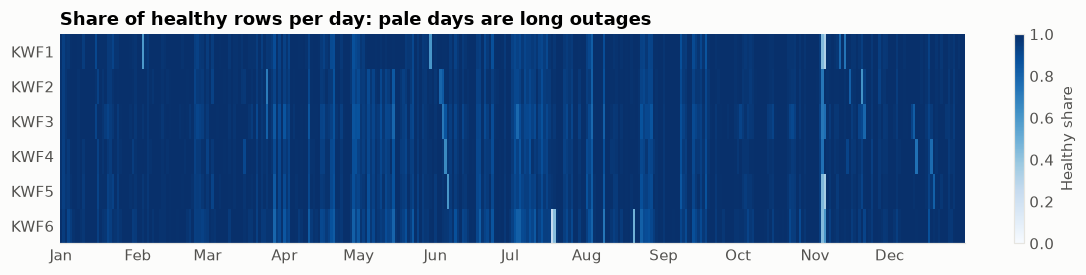

In [8]:
fig, ax = plt.subplots(figsize=(10, 2.6))
hm = df.assign(day=df.ts.dt.floor("D")).groupby(["turbine", "day"])["healthy"].mean().unstack("day")
im = ax.imshow(hm.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(hm)), hm.index); ax.grid(False)
ticks = [i for i, d in enumerate(hm.columns) if d.day == 1]
ax.set_xticks(ticks, [hm.columns[i].strftime("%b") for i in ticks])
ax.set_title("Share of healthy rows per day: pale days are long outages")
fig.colorbar(im, ax=ax, fraction=0.015, label="Healthy share"); plt.tight_layout(); plt.show()

**What this shows**

- **Completeness:** power and wind are missing in 0.10–0.16% of rows. Temperature, pitch and turbulence are missing in 0.88%. Of 71 gaps, 51 are 30 minutes or less and the longest is 6 hours.
- **Bad values:** no wind sensor is stuck for 2 hours, no power is below −5% of rated, and the maximum is 101.8% of rated. Slightly negative power in about 10% of rows is the turbine drawing standby power in calm air, so it's normal.
- **Outages:** the pale band in early November is a shared event. On 4 November, KWF1, KWF5 and KWF6 stopped for 16–23 hours within about half an hour of each other, with connection and converter messages. Comparing turbines against each other should cancel events like this.
- **Limit for the models:** the highest wind in 2019 is 23.7 m/s, so the data has **no shutdown at the 25 m/s cut-out**. The models can't learn it from this year.

## 3. Wind and production

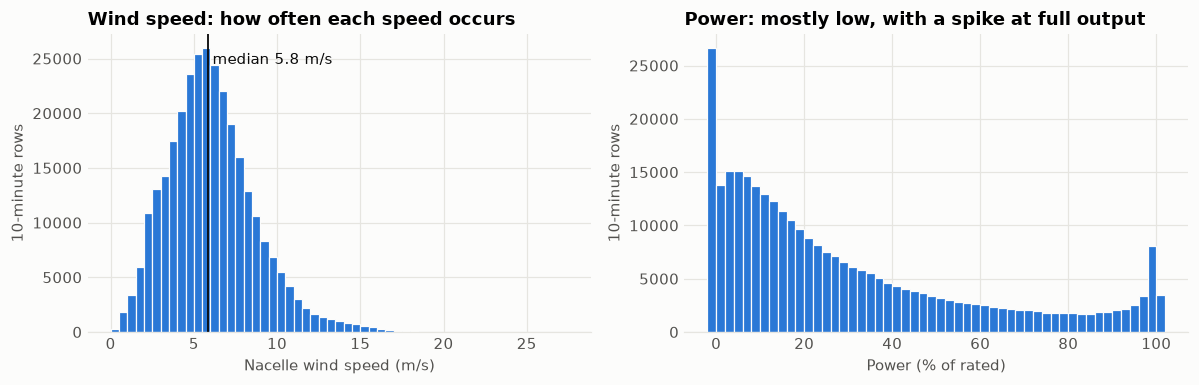

Capacity factor (mean power / rated, all rows): 28.7%
Share of healthy rows below 5% of rated: 20.6%; at 95%+ of rated: 5.3%
Energy per turbine in 2019 (MWh): KWF1 5,287, KWF2 5,897, KWF3 4,968, KWF4 5,460, KWF5 4,943, KWF6 4,316


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
h = df[df.healthy]
axes[0].hist(h.wind_ms, bins=np.arange(0, 28, 0.5), color=BLUE, edgecolor=SURFACE, linewidth=0.8)
axes[0].axvline(h.wind_ms.median(), color=INK, linewidth=1.2); axes[0].text(h.wind_ms.median() + 0.3, axes[0].get_ylim()[1] * 0.9, f"median {h.wind_ms.median():.1f} m/s", color=INK)
axes[0].set_title("Wind speed: how often each speed occurs"); axes[0].set_xlabel("Nacelle wind speed (m/s)"); axes[0].set_ylabel("10-minute rows")
axes[1].hist(h.frac * 100, bins=np.arange(-2, 104, 2), color=BLUE, edgecolor=SURFACE, linewidth=0.8)
axes[1].set_title("Power: mostly low, with a spike at full output"); axes[1].set_xlabel("Power (% of rated)"); axes[1].set_ylabel("10-minute rows")
plt.tight_layout(); plt.show()
print(f"Capacity factor (mean power / rated, all rows): {df.power_kw.mean() / RATED:.1%}")
print(f"Share of healthy rows below 5% of rated: {(h.frac < 0.05).mean():.1%}; at 95%+ of rated: {(h.frac >= 0.95).mean():.1%}")
print(f"Energy per turbine in 2019 (MWh): " + ", ".join(f"{t} {v:,.0f}" for t, v in (df.groupby('turbine').power_kw.sum() / 6 / 1000).items()))

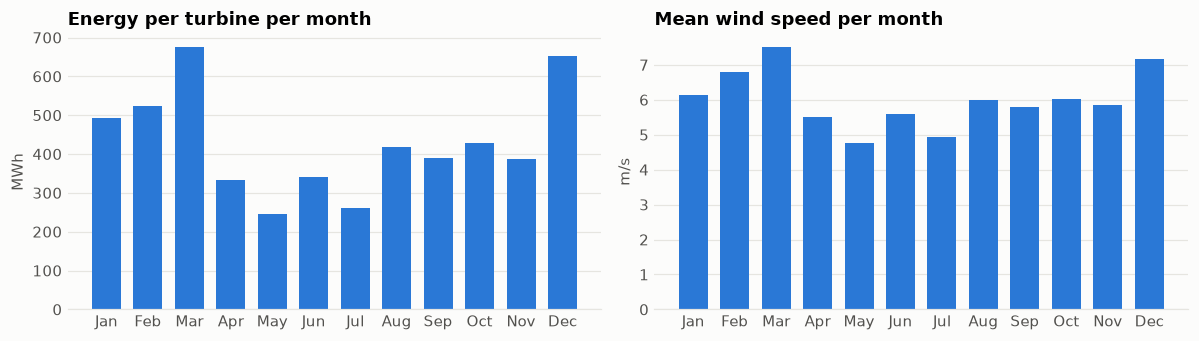

month  2019-01  2019-02  2019-03  2019-04  2019-05  2019-06  2019-07  2019-08  2019-09  2019-10  2019-11  2019-12
wind       6.1      6.8      7.5      5.5      4.8      5.6      4.9      6.0      5.8      6.0      5.9      7.2
mwh      491.5    523.7    674.9    334.0    245.6    340.4    260.7    417.7    388.8    428.4    387.6    651.9

Mean output by hour of day (UTC): lowest 26.8% at 2:00, highest 32.6% at 12:00


In [10]:
m = df.assign(month=df.ts.dt.to_period("M").astype(str)).groupby("month").agg(wind=("wind_ms", "mean"), mwh=("power_kw", lambda s: s.sum() / 6 / 1000 / 6))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
labels = [pd.Period(x).strftime("%b") for x in m.index]
axes[0].bar(labels, m.mwh, color=BLUE, width=0.7); axes[0].set_title("Energy per turbine per month"); axes[0].set_ylabel("MWh"); axes[0].grid(axis="x", visible=False)
axes[1].bar(labels, m.wind, color=BLUE, width=0.7); axes[1].set_title("Mean wind speed per month"); axes[1].set_ylabel("m/s"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(m.round(1).T.to_string())
hour = df.assign(hour=df.ts.dt.hour).groupby("hour").frac.mean() * 100
print(f"\nMean output by hour of day (UTC): lowest {hour.min():.1f}% at {hour.idxmin()}:00, highest {hour.max():.1f}% at {hour.idxmax()}:00")

**What this shows**

- **Output is low most of the time:** capacity factor is 28.7%. About 21% of healthy rows are below 5% of rated and only 5% are near full output. That's why there are cheap days to find.
- **Strong seasons:** per turbine, March gives 675 MWh and May 246 MWh. The time of day matters far less (27–33% of rated), so the *day* is the decision that matters most.
- **Turbines differ:** yearly energy runs from 4,316 MWh (KWF6) to 5,897 MWh (KWF2).

## 4. Power curve

Each point is 10 minutes of one turbine. The healthy cloud is what M1 has to learn. Everything far from it is a stop, a limit or a fault.

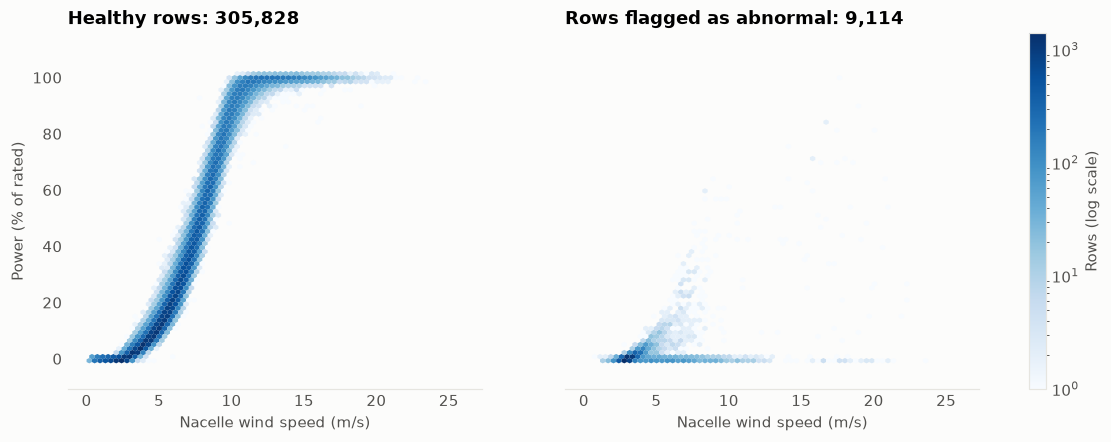

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True, sharex=True)
for ax, sel, title in ((axes[0], df.healthy, "Healthy rows"), (axes[1], ~df.healthy, "Rows flagged as abnormal")):
    p = df[sel].dropna(subset=["wind_ms", "frac"])
    hb = ax.hexbin(p.wind_ms, p.frac * 100, gridsize=70, bins="log", cmap="Blues", mincnt=1, extent=(0, 26, -5, 110), linewidths=0)
    ax.set_title(f"{title}: {len(p):,}"); ax.set_xlabel("Nacelle wind speed (m/s)"); ax.grid(False)
axes[0].set_ylabel("Power (% of rated)")
fig.colorbar(hb, ax=axes, fraction=0.02, label="Rows (log scale)"); plt.show()

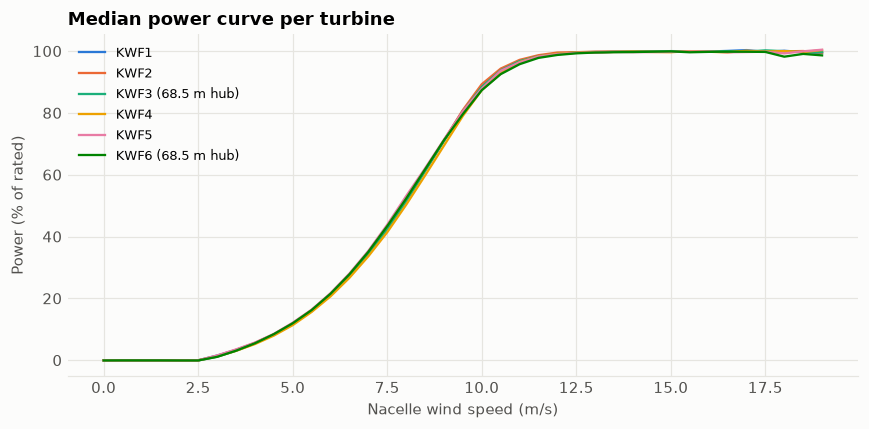

Spread at a given wind speed, 10th to 90th percentile (% of rated):
bin
3.0      3.1
5.0      6.3
7.0     11.5
9.0     14.6
11.0     7.8
13.0     2.4
15.0     1.8

Median power at 9 m/s per turbine (% of rated): {'KWF1': 71.0, 'KWF2': 71.1, 'KWF3': 70.9, 'KWF4': 69.4, 'KWF5': 71.3, 'KWF6': 71.2}
Cut-in: wind where median power first exceeds 2%: 3.5 m/s; reaches 98% of rated at: 11.5 m/s


In [12]:
h = df[df.healthy].copy()
h["bin"] = (h.wind_ms / 0.5).round() * 0.5
curve = h.groupby("bin").frac.agg(["median", lambda s: s.quantile(.1), lambda s: s.quantile(.9), "size"]); curve.columns = ["p50", "p10", "p90", "n"]
curve = curve[curve.n >= 20]
fig, ax = plt.subplots(figsize=(8, 4))
for t, g in h.groupby("turbine"):
    c = g.groupby("bin").frac.median().reindex(curve.index)
    ax.plot(c.index, c * 100, color=TURBINE_COLOR[t], linewidth=1.5, label=t + (" (68.5 m hub)" if t in ("KWF3", "KWF6") else ""))
ax.set_title("Median power curve per turbine"); ax.set_xlabel("Nacelle wind speed (m/s)"); ax.set_ylabel("Power (% of rated)"); ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()
print("Spread at a given wind speed, 10th to 90th percentile (% of rated):")
print(((curve.p90 - curve.p10) * 100).loc[[3, 5, 7, 9, 11, 13, 15]].round(1).to_string())
sel = h[h.wind_ms.between(8.75, 9.25)]
print("\nMedian power at 9 m/s per turbine (% of rated):", (sel.groupby('turbine').frac.median() * 100).round(1).to_dict())
print("Cut-in: wind where median power first exceeds 2%:", curve.index[(curve.p50 > 0.02)][0], "m/s; reaches 98% of rated at:", curve.index[(curve.p50 >= 0.98)][0], "m/s")

**What this shows**

- **M1's job:** the healthy cloud is tight, and the curves of all six turbines nearly overlap, even KWF3 and KWF6 with their lower hubs. Output starts around 3.5 m/s and reaches 98% of rated by 11.5 m/s.
- **Where it's hard:** the spread peaks at about 15 points of rated around 9 m/s, and is only about 2 points above 13 m/s. Expect M1's largest errors in the 7–11 m/s range.
- **The filter works:** abnormal rows sit at zero or well below the curve. At 7+ m/s, 74% of them produce under 2% of rated.
- **Sparse at the top:** only 183 rows are above 18 m/s, so scores above that speed will rest on little data.

## 5. Status log

What the turbines report about themselves, and how much of it matters.

In [13]:
print("Events by Status:"); print(events.groupby("Status").agg(events=("hours", "size"), with_duration=("hours", "count"), total_hours=("hours", "sum")).round(0).to_string())
print("\nEvents by IEC category:"); print(events.groupby("IEC category").agg(events=("hours", "size"), total_hours=("hours", "sum")).round(0).to_string())
stops = events[events.Status == "Stop"].groupby("Message").agg(stops=("hours", "size"), total_hours=("hours", "sum"), longest_h=("hours", "max")).sort_values("total_hours", ascending=False)
print("\nStops by cause, all turbines (the real downtime):"); print(stops.head(14).round(1).to_string())
print("\nStop hours per turbine:", events[events.Status == "Stop"].groupby("turbine").hours.sum().round(0).to_dict())

Events by Status:
               events  with_duration  total_hours
Status                                           
Communication      58             58        468.0
Informational   58082           6899        275.0
Stop              673            673        358.0
Warning           513            513       2707.0

Events by IEC category:
                                    events  total_hours
IEC category                                           
                                       277       3043.0
Forced outage                          146        251.0
Full Performance                     36010        180.0
Out of Electrical Specification         42         50.0
Out of Environmental Specification   13424        109.0
Scheduled Maintenance                   64        122.0
Technical Standby                     9363         52.0

Stops by cause, all turbines (the real downtime):
                                  stops  total_hours  longest_h
Message                               

In [14]:
long = events[(events.Status == "Stop")].sort_values("hours", ascending=False).head(12)
print("The 12 longest stops:"); display(long[["turbine", "start", "hours", "Message", "IEC category"]].round(1))
w = events[events.Status == "Warning"].groupby("Message").agg(n=("hours", "size"), hours=("hours", "sum")).sort_values("hours", ascending=False).head(6)
print("Longest-running warnings (the turbine keeps producing):"); print(w.round(0).to_string())

The 12 longest stops:


,turbine,start,hours,Message,IEC category
54453,KWF6,2019-07-18 06:01:58,31.4,Batt. undervoltage/overvoltage,Forced outage
7057,KWF1,2019-11-04 17:18:46,22.6,Timeout ready for connection,Out of Electrical Specification
44909,KWF5,2019-11-04 17:22:13,21.7,Timeout ready for connection,Out of Electrical Specification
58514,KWF6,2019-11-04 17:44:08,15.7,Frequency converter not ready,Forced outage
55879,KWF6,2019-08-20 09:55:10,10.1,Manual stop - on site,Scheduled Maintenance
414,KWF1,2019-02-03 04:00:30,9.7,Icing (stop),Out of Environmental Specification
15161,KWF2,2019-11-20 10:53:30,8.9,Manual stop - remote,Forced outage
2799,KWF1,2019-05-30 07:15:57,6.9,Manual stop - on site,Scheduled Maintenance
31150,KWF4,2019-06-05 09:06:02,6.4,Manual stop - on site,Scheduled Maintenance
40222,KWF5,2019-06-06 06:58:28,6.4,Manual stop - on site,Scheduled Maintenance


Longest-running warnings (the turbine keeps producing):
                           n   hours
Message                             
Oil filter gear choked     3  1974.0
Breakdown obstacle light   5   394.0
Timeout brake closed      38    64.0
Overload generator fan 3  23    42.0
Overload generator fan 2  23    42.0
Overload generator fan 1  23    42.0


**What this shows**

- **Real downtime is small:** of 59,326 events, only 673 are stops, totalling 358 hours, or about 0.7% of turbine time. Manual stops on site are the largest cause, at 103 hours.
- **Real service times look shorter than assumed:** `Scheduled Maintenance` totals 122 hours, about 20 hours per turbine per year. Our drafted assumption was 40 hours (16 h + 24 h revisions), so it should be revisited in the optimizer step.
- **Warnings don't mean underperformance:** the longest one, a choked gear oil filter on KWF1, ran for nearly 2,000 hours. Section 9 shows no visible effect on power or gear oil temperature, so warnings are correctly left out of the abnormal rule.
- **Only one icing stop** in the whole year, on KWF1 on 3 February.

## 6. Do the turbines agree?

Comparing a turbine with its neighbours is central to M2, so this checks how closely they track each other, and whether any turbine drifts during the year.

Hourly power correlation with the median of the other turbines:
{'KWF1': 0.966, 'KWF2': 0.966, 'KWF3': 0.94, 'KWF4': 0.958, 'KWF5': 0.957, 'KWF6': 0.956}

Mean wind reading relative to the fleet median:


{'KWF1': 0.994, 'KWF2': 1.041, 'KWF3': 0.977, 'KWF4': 1.022, 'KWF5': 0.961, 'KWF6': 0.915}


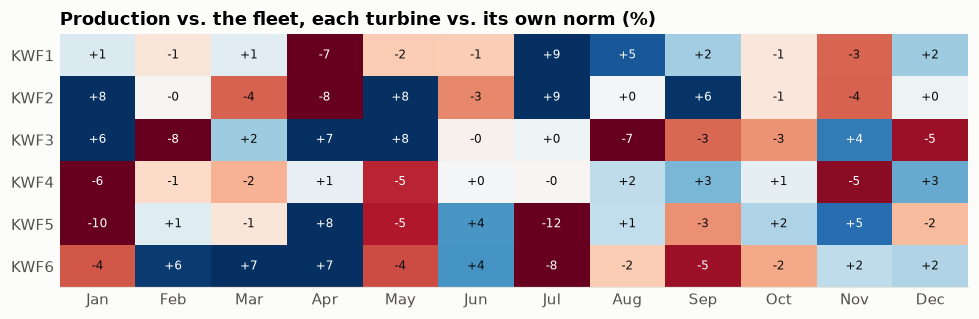

Turbine-months more than 3% off their norm: 37 of 72 ; largest 11.7%


In [15]:
hourly = df.assign(hour=df.ts.dt.floor("h"))
P = hourly[hourly.healthy].groupby(["hour", "turbine"]).power_kw.mean().unstack()
W = hourly[hourly.healthy].groupby(["hour", "turbine"]).wind_ms.mean().unstack()
print("Hourly power correlation with the median of the other turbines:")
print({t: round(float(P[t].corr(P.drop(columns=t).median(axis=1))), 3) for t in P})
print("\nMean wind reading relative to the fleet median:")
ratio = W.div(W.median(axis=1), axis=0).mean()
print(ratio.round(3).to_dict())
# Each turbine against the rest of the fleet, month by month: a persistent colour shift would be real underperformance.
keep = P.notna().all(axis=1)
rel = {}
for t in P:
    others = P.drop(columns=t).median(axis=1)
    rel[t] = (P[t][keep].groupby(P.index[keep].to_period("M")).sum() / others[keep].groupby(P.index[keep].to_period("M")).sum())
rel = pd.DataFrame(rel); rel = rel / rel.median()
fig, ax = plt.subplots(figsize=(9, 3.0))
im = ax.imshow((rel.T.to_numpy() - 1) * 100, aspect="auto", cmap="RdBu", vmin=-6, vmax=6)
ax.set_yticks(range(6), rel.columns); ax.set_xticks(range(len(rel)), [p.strftime("%b") for p in rel.index]); ax.grid(False)
for i in range(rel.shape[1]):
    for j in range(rel.shape[0]):
        ax.text(j, i, f"{(rel.iloc[j, i] - 1) * 100:+.0f}", ha="center", va="center", fontsize=8, color="white" if abs(rel.iloc[j, i] - 1) > 0.04 else INK)
ax.set_title("Production vs. the fleet, each turbine vs. its own norm (%)"); plt.tight_layout(); plt.show()
print("Turbine-months more than 3% off their norm:", int(((rel - 1).abs() > 0.03).sum().sum()), "of", rel.size, f"; largest {(rel - 1).abs().max().max():.1%}")

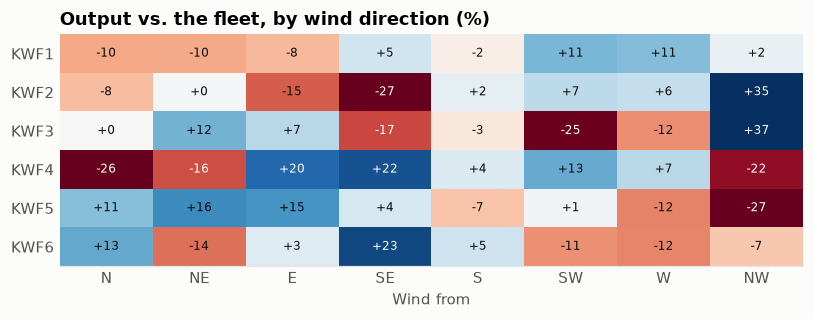

Hours per direction: {'N': 599, 'NE': 721, 'E': 662, 'SE': 675, 'S': 1236, 'SW': 2179, 'W': 1593, 'NW': 1091}
Largest direction effect per turbine (%): {'KWF1': 21.0, 'KWF2': 62.0, 'KWF3': 62.0, 'KWF4': 48.0, 'KWF5': 43.0, 'KWF6': 37.0}


In [16]:
# Why would a healthy turbine drift against its neighbours? Test wind direction: upwind turbines shelter downwind ones.
dirs = hourly[hourly.healthy].groupby("hour").wind_dir_deg.median()
sector = ((dirs + 22.5) // 45 % 8).reindex(P.index)
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
windy = P.median(axis=1).between(0.1 * RATED, 0.85 * RATED)
tab = {t: P[t][windy].groupby(sector[windy]).sum() / P.drop(columns=t).median(axis=1)[windy].groupby(sector[windy]).sum() for t in P}
tab = pd.DataFrame(tab); tab.index = [names[int(i)] for i in tab.index]
tab = tab / tab.mean()
fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.imshow((tab.T.to_numpy() - 1) * 100, aspect="auto", cmap="RdBu", vmin=-25, vmax=25)
ax.set_yticks(range(6), tab.columns); ax.set_xticks(range(8), tab.index); ax.grid(False)
for i in range(6):
    for j in range(8):
        ax.text(j, i, f"{(tab.iloc[j, i] - 1) * 100:+.0f}", ha="center", va="center", fontsize=8, color="white" if abs(tab.iloc[j, i] - 1) > 0.16 else INK)
ax.set_title("Output vs. the fleet, by wind direction (%)"); ax.set_xlabel("Wind from"); plt.tight_layout(); plt.show()
print("Hours per direction:", {names[int(k)]: int(v) for k, v in sector.value_counts().sort_index().items()})
print("Largest direction effect per turbine (%):", ((tab.max() - tab.min()) * 100).round(0).to_dict())

**What this shows**

- **Hour by hour, they move together:** correlation with the rest of the fleet is 0.94–0.97.
- **But raw comparisons are noisy:** 37 of 72 turbine-months are more than 3% off their norm, up to 11.7%, with no fault involved. The direction table suggests why: a turbine's output relative to the fleet swings by 21–62 points with wind direction. That fits turbines sheltering each other, though the data alone doesn't prove it.
- **For M2:** a faulty turbine can't be spotted by comparing raw power with its neighbours. A yaw fault losing 0.5–7% would be buried in this noise. The comparison has to use each turbine's deviation from its *expected* power given its own wind, which section 4 shows is far tighter. The drafted M2 feature `power_vs_fleet_change` needs testing against this.

## 7. Nacelle wind vs. weather data

M1 reads the nacelle anemometer, but a forecast only gives wind from a weather model. If the two differ, a power curve fitted on one can't simply be fed the other. This is why M4 gets its own weather-based model.

Correlation, nacelle wind vs. weather-model wind: 0.915
Mean nacelle 6.10 m/s, mean weather model at 100 m 7.54 m/s; typical absolute difference 1.63 m/s


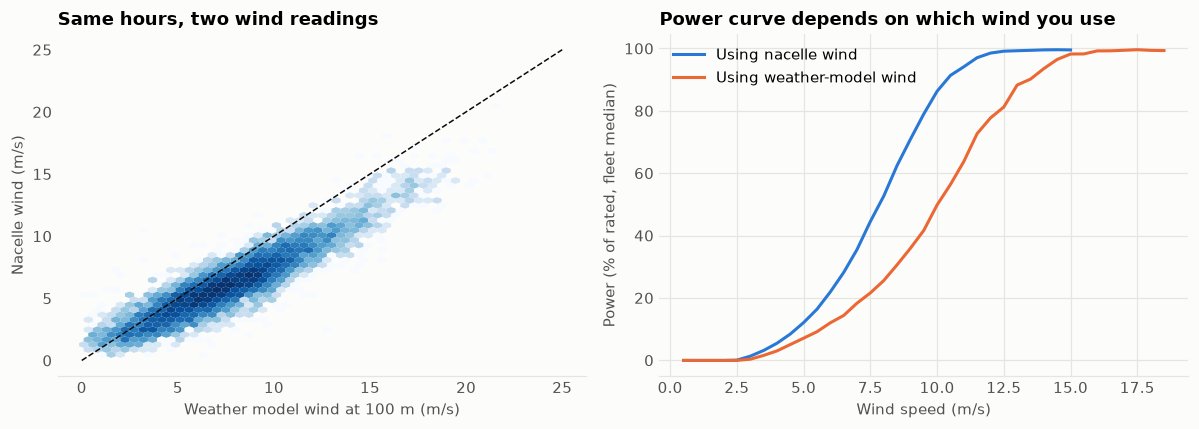

Hourly error predicting fleet power from nacelle wind with a binned curve: 1.8% of rated
Hourly error predicting fleet power from weather wind with a binned curve: 7.8% of rated


In [17]:
w = wx
j = pd.DataFrame({"nacelle": W.median(axis=1), "weather": w.wind_speed_100m, "power": P.median(axis=1) / RATED * 100}).dropna()
print(f"Correlation, nacelle wind vs. weather-model wind: {j.nacelle.corr(j.weather):.3f}")
print(f"Mean nacelle {j.nacelle.mean():.2f} m/s, mean weather model at 100 m {j.weather.mean():.2f} m/s; typical absolute difference {(j.nacelle - j.weather).abs().mean():.2f} m/s")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
axes[0].hexbin(j.weather, j.nacelle, gridsize=45, cmap="Blues", bins="log", mincnt=1, linewidths=0); axes[0].plot([0, 25], [0, 25], color=INK, linewidth=1, linestyle="--")
axes[0].set_xlabel("Weather model wind at 100 m (m/s)"); axes[0].set_ylabel("Nacelle wind (m/s)"); axes[0].set_title("Same hours, two wind readings"); axes[0].grid(False)
for col, c, lab in (("nacelle", BLUE, "Using nacelle wind"), ("weather", ORANGE, "Using weather-model wind")):
    g = j.groupby((j[col] * 2).round() / 2).power.agg(["median", "size"]); g = g[g["size"] >= 10]
    axes[1].plot(g.index, g["median"], color=c, linewidth=2, label=lab)
axes[1].set_xlabel("Wind speed (m/s)"); axes[1].set_ylabel("Power (% of rated, fleet median)"); axes[1].set_title("Power curve depends on which wind you use"); axes[1].legend()
plt.tight_layout(); plt.show()
for col in ("nacelle", "weather"):
    g = j.groupby((j[col] * 2).round() / 2).power.transform("median")
    print(f"Hourly error predicting fleet power from {col} wind with a binned curve: {(j.power - g).abs().mean():.1f}% of rated")

**What this shows**

- **The two winds differ:** correlation is 0.915, but nacelle wind averages 6.10 m/s against 7.54 m/s from the weather model at 100 m, and individual hours differ by 1.63 m/s on average.
- **Feeding forecast wind into a nacelle-based curve would be wrong:** the right chart shows the same power at very different speeds. At 10 m/s the two curves are far apart. This confirms M4 needs its own model.
- **Expect weaker accuracy from M4 than M1:** a simple curve gives 7.8% of rated hourly error from weather wind vs. 1.8% from nacelle wind, even before any forecast error. That may still be enough to rank days, which we'll test in that step.

## 8. Does choosing the day matter?

The project's core claim is that picking the right day for maintenance saves energy. This tests it directly on what the turbines really produced: for each day, what would an 8-hour stop in the 07:00–15:00 UTC shift have cost?

Cost of an 8-hour stop, per turbine, MWh: median 3.6, 10th pct 0.2, 90th pct 11.8, max 16.2


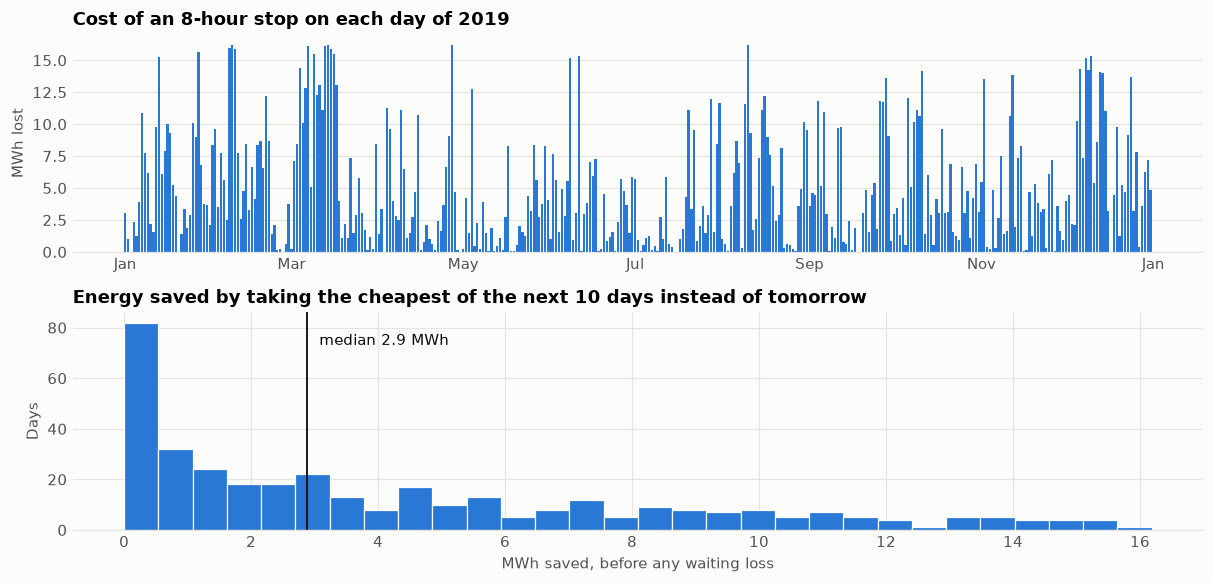

Saving vs. going tomorrow, with perfect knowledge: mean 4.3, median 2.9 MWh per job
Share of days where tomorrow is already the cheapest: 12%. Mean days to the cheapest day: 4.4
With a fault losing 1.4 MWh/day while waiting (design doc example): mean net saving 1.9 MWh per job, median 0.0
Assumed 12 m/s climb limit: 84% of days stay under it for the whole shift; 96% of shift rows are under it
Using the fleet's hourly wind: 93% of days are workable for the whole shift. Mean stop cost on workable days 4.3 MWh, on unworkable days 14.8 MWh

Next safe day vs. best safe day in the next 10, perfect knowledge of the weather:


,fault loss (MWh/day),mean saving (MWh/job),median saving,days worth waiting,mean extra wait (days)
0,0.0,3.91,2.78,0.89,4.30
1,0.2,3.25,1.99,0.74,2.50
2,0.5,2.64,1.19,0.63,1.63
3,1.0,1.99,0.05,0.50,0.99
4,1.4,1.63,0.00,0.45,0.84
5,3.0,0.78,0.00,0.27,0.34


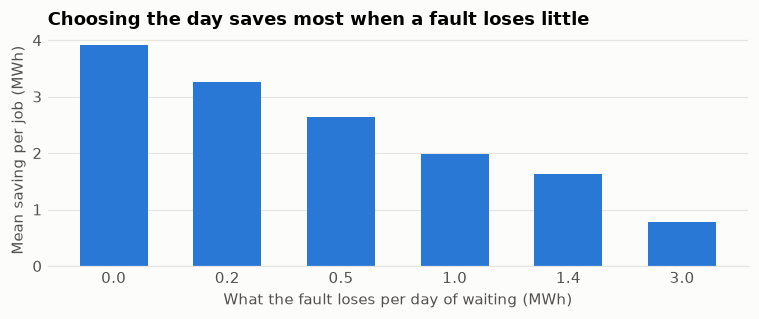


Cheapest days: {'03 Jan': 0.0, '19 Sep': 0.0, '15 Jul': 0.0, '30 Apr': 0.0} 
Dearest days: {'27 Apr': 16.2, '14 Mar': 16.2, '08 Feb': 16.2, '10 Aug': 16.2}

day                1    2    3     4     5     6     7     8     9    10    11   12
median_mwh        3.9  6.1  7.3   2.6   1.8   3.4   1.4   4.9   3.3  3.5   3.2  6.2
days_under_2_mwh  7.0  5.0  8.0  12.0  16.0  11.0  19.0  10.0  12.0  8.0  13.0  3.0


In [18]:
SHIFT = (7, 15)
d = df.assign(day=df.ts.dt.floor("D"), hour=df.ts.dt.hour)
shift = d[(d.hour >= SHIFT[0]) & (d.hour < SHIFT[1])]
cost = shift.groupby(["day", "turbine"]).power_kw.mean().clip(lower=0).mul((SHIFT[1] - SHIFT[0]) / 1000).unstack()
day_cost = cost.mean(axis=1)
print(f"Cost of an 8-hour stop, per turbine, MWh: median {day_cost.median():.1f}, 10th pct {day_cost.quantile(.1):.1f}, 90th pct {day_cost.quantile(.9):.1f}, max {day_cost.max():.1f}")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.4))
axes[0].bar(day_cost.index, day_cost, color=BLUE, width=0.8); axes[0].set_title("Cost of an 8-hour stop on each day of 2019"); axes[0].set_ylabel("MWh lost"); axes[0].grid(axis="x", visible=False)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
H = 10
fut = pd.concat([day_cost.shift(-k) for k in range(1, H + 1)], axis=1)
saving = fut.iloc[:, 0] - fut.min(axis=1)
axes[1].hist(saving.dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.8); axes[1].axvline(saving.median(), color=INK, linewidth=1.2); axes[1].text(saving.median() + 0.2, axes[1].get_ylim()[1] * 0.85, f"median {saving.median():.1f} MWh", color=INK)
axes[1].set_title(f"Energy saved by taking the cheapest of the next {H} days instead of tomorrow"); axes[1].set_xlabel("MWh saved, before any waiting loss"); axes[1].set_ylabel("Days")
plt.tight_layout(); plt.show()
LOSS = 1.4
days_to_best = fut.to_numpy().argmin(axis=1)
net = saving - LOSS * days_to_best
print(f"Saving vs. going tomorrow, with perfect knowledge: mean {saving.mean():.1f}, median {saving.median():.1f} MWh per job")
print(f"Share of days where tomorrow is already the cheapest: {(saving == 0).mean():.0%}. Mean days to the cheapest day: {days_to_best.mean():.1f}")
best = (fut.values + np.arange(0, H)[None, :] * LOSS).min(axis=1)
smart = fut.iloc[:, 0].to_numpy() - best
print(f"With a fault losing {LOSS} MWh/day while waiting (design doc example): mean net saving {np.nanmean(smart):.1f} MWh per job, median {np.nanmedian(smart):.1f}")
wm = d[(d.hour >= SHIFT[0]) & (d.hour < SHIFT[1])].groupby("day").wind_ms.max()
safe = (wm < 12).mean(); hrs = d[(d.hour >= SHIFT[0]) & (d.hour < SHIFT[1])]
print(f"Assumed 12 m/s climb limit: {safe:.0%} of days stay under it for the whole shift; {(hrs.wind_ms < 12).mean():.0%} of shift rows are under it")
wind_hours = hrs.groupby(["day", "hour"]).wind_ms.median().groupby("day").max()
workable = (wind_hours < 12).reindex(day_cost.index).fillna(False)
print(f"Using the fleet's hourly wind: {workable.mean():.0%} of days are workable for the whole shift. Mean stop cost on workable days {day_cost[workable].mean():.1f} MWh, on unworkable days {day_cost[~workable].mean():.1f} MWh")
safe_cost = day_cost.where(workable).to_numpy()
idx = np.arange(len(safe_cost))
table = []
for loss in (0, 0.2, 0.5, 1.0, 1.4, 3.0):
    nets, waits = [], []
    for i in idx[:-H]:
        c = safe_cost[i + 1: i + H + 1]
        if np.isnan(c).all():
            continue
        first = np.nanargmin(np.where(np.isnan(c), np.nan, np.arange(H, dtype=float)))  # The next safe day.
        total = c + loss * np.arange(H)
        best_i = np.nanargmin(total)
        nets.append(total[first] - total[best_i]); waits.append(best_i - first)
    table.append({"fault loss (MWh/day)": loss, "mean saving (MWh/job)": np.mean(nets), "median saving": np.median(nets), "days worth waiting": np.mean(np.array(waits) > 0), "mean extra wait (days)": np.mean(waits)})
table = pd.DataFrame(table).round(2); print("\nNext safe day vs. best safe day in the next 10, perfect knowledge of the weather:"); display(table)
fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(table.iloc[:, 0].astype(str), table["mean saving (MWh/job)"], color=BLUE, width=0.6); ax.grid(axis="x", visible=False)
ax.set_title("Choosing the day saves most when a fault loses little"); ax.set_xlabel("What the fault loses per day of waiting (MWh)"); ax.set_ylabel("Mean saving per job (MWh)"); plt.tight_layout(); plt.show()
worst = day_cost.sort_values(); print("\nCheapest days:", {k.strftime('%d %b'): round(v, 2) for k, v in worst.head(4).items()}, "\nDearest days:", {k.strftime('%d %b'): round(v, 1) for k, v in worst.tail(4).items()})
by_month = day_cost.groupby(day_cost.index.month).agg(["median", lambda s: (s < 2).sum()]); by_month.columns = ["median_mwh", "days_under_2_mwh"]; print(); print(by_month.round(1).T.to_string())

**What this shows: the project's main claim, tested on real production**

- **Days really do differ:** an 8-hour stop costs 3.6 MWh on a median day, from 0.2 (10th percentile) up to 11.8 (90th), with a maximum of 16.2.
- **The safety limit already avoids the worst days:** under an assumed 12 m/s climb limit, days that aren't workable average 14.8 MWh, and those that are average 4.3. So "go on the next safe day" is the fair comparison, and that's what the table uses.
- **Choosing the day saves most for cheap-to-delay jobs:** about 3.9 MWh per 8-hour job when waiting costs nothing, such as a revision within its window, falling to 1.6 at 1.4 MWh/day and 0.8 at 3 MWh/day.
- **Many real faults are in the useful range:** at about 14 MWh/day per turbine, even a 15° yaw fault (6.7% loss) loses under 1 MWh/day. Pitch and icing faults can lose more.

**Limits:** these use perfect knowledge of the weather, so they're an upper bound, and real forecasts will save less. They also cover a single 8-hour job, so multi-day revisions would scale up. And the design doc's 18 MWh stop is above this site's maximum of 16.2 MWh, though about right for a 2.5 MW turbine at full power, so it shouldn't be presented as typical.

## 9. Browse samples

Change the arguments and re-run a cell.

- `show_week(turbine, start, days)`: wind and power over time, with stops shaded.
- `rows(...)`: random rows, optionally filtered.
- `suspects(...)`: healthy rows where power falls far below normal for that wind, the kind of thing M2 should catch.

In [19]:
SHOW = ["ts", "turbine", "power_kw", "frac", "wind_ms", "wind_std_ms", "wind_dir_deg", "nacelle_deg", "pitch_deg", "rotor_rpm", "temp_c", "gear_oil_c", "healthy"]


def show_week(turbine="KWF1", start="2019-03-10", days=7):
    """Wind and power over time for one turbine, with abnormal rows and stop events marked."""
    t0, t1 = pd.Timestamp(start), pd.Timestamp(start) + pd.Timedelta(days=days)
    g = df[(df.turbine == turbine) & (df.ts >= t0) & (df.ts < t1)]
    if g.empty:
        print("No data for that turbine and period. Turbines are KWF1 to KWF6; dates are in 2019."); return
    fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
    axes[0].plot(g.ts, g.wind_ms, color=BLUE, linewidth=1.1); axes[0].set_ylabel("Wind (m/s)"); axes[0].axhline(12, color=MUTED, linewidth=0.8, linestyle="--")
    axes[0].text(g.ts.iloc[0], 12.3, "assumed 12 m/s climb limit", color=MUTED, fontsize=8)
    axes[1].plot(g.ts, g.frac * 100, color=BLUE, linewidth=1.1); axes[1].set_ylabel("Power (% of rated)")
    for ax in axes:
        bad = (~g.healthy).to_numpy()
        ax.fill_between(g.ts, *ax.get_ylim(), where=bad, color=ORANGE, alpha=0.25, linewidth=0, step="mid")
    axes[0].set_title(f"{turbine}, from {t0:%d %b %Y} (orange: flagged abnormal)")
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); plt.tight_layout(); plt.show()
    ev = events[(events.turbine == turbine) & (events.start >= t0) & (events.start < t1) & (events.Status == "Stop")]
    print(f"Mean wind {g.wind_ms.mean():.1f} m/s, energy {g.power_kw.sum() / 6 / 1000:.1f} MWh, healthy {g.healthy.mean():.0%}, {len(ev)} stops")
    if len(ev):
        display(ev[["start", "hours", "Message", "IEC category"]].round(2).head(10))


def rows(n=8, seed=None, where=None):
    """Random rows. where is a filter, e.g. "wind_ms > 15" or "turbine == 'KWF3' and temp_c < 0"."""
    g = df.query(where) if where else df
    print(f"{len(g):,} rows match")
    return g.sample(min(n, len(g)), random_state=seed)[SHOW].sort_values("ts").round(2)


typical = df[df.healthy].assign(bin=lambda x: (x.wind_ms * 2).round() / 2).groupby("bin").frac.median()


def suspects(n=8, min_wind=7, seed=1, turbine=None, min_shortfall=0.15):
    """Healthy rows with power far below the typical value for their wind."""
    g = df[df.healthy & (df.wind_ms >= min_wind)]
    if turbine:
        g = g[g.turbine == turbine]
    g = g.assign(typical=((g.wind_ms * 2).round() / 2).map(typical))
    g = g.assign(shortfall=g.typical - g.frac)
    bad = g[g.shortfall > min_shortfall]
    print(f"{len(bad):,} of {len(g):,} healthy rows at {min_wind}+ m/s are over {min_shortfall:.0%} of rated below typical ({len(bad) / max(len(g), 1):.2%})")
    return bad.sample(min(n, len(bad)), random_state=seed)[["ts", "turbine", "power_kw", "frac", "typical", "wind_ms", "wind_std_ms", "pitch_deg", "rotor_rpm", "temp_c"]].sort_values("ts").round(2)

**A windy week and a calm week** (dates picked from section 8's dearest and cheapest days):

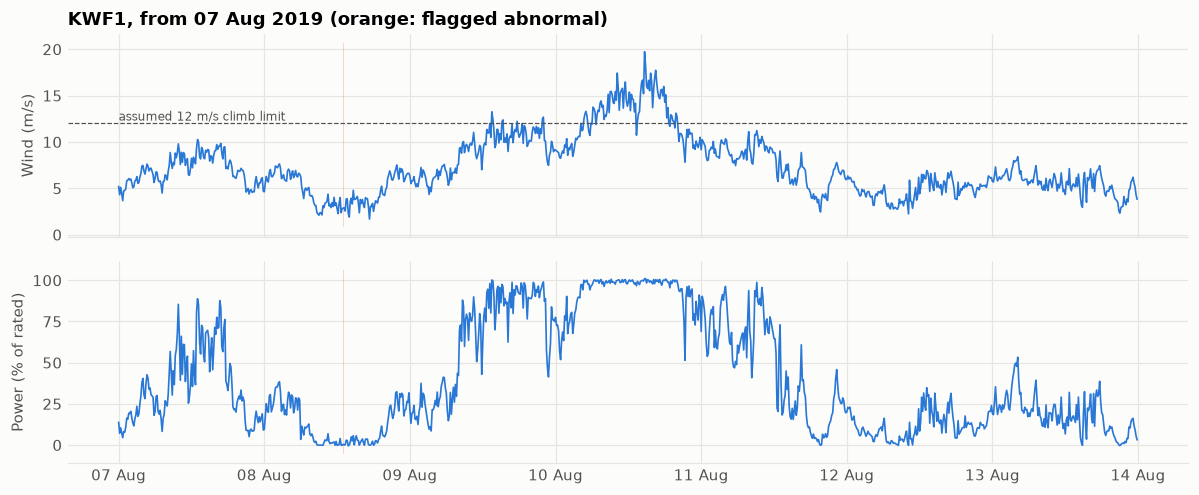

Mean wind 7.3 m/s, energy 138.8 MWh, healthy 98%, 1 stops


,start,hours,Message,IEC category
5264,2019-08-08 06:00:00,0.04,Battery test,Technical Standby


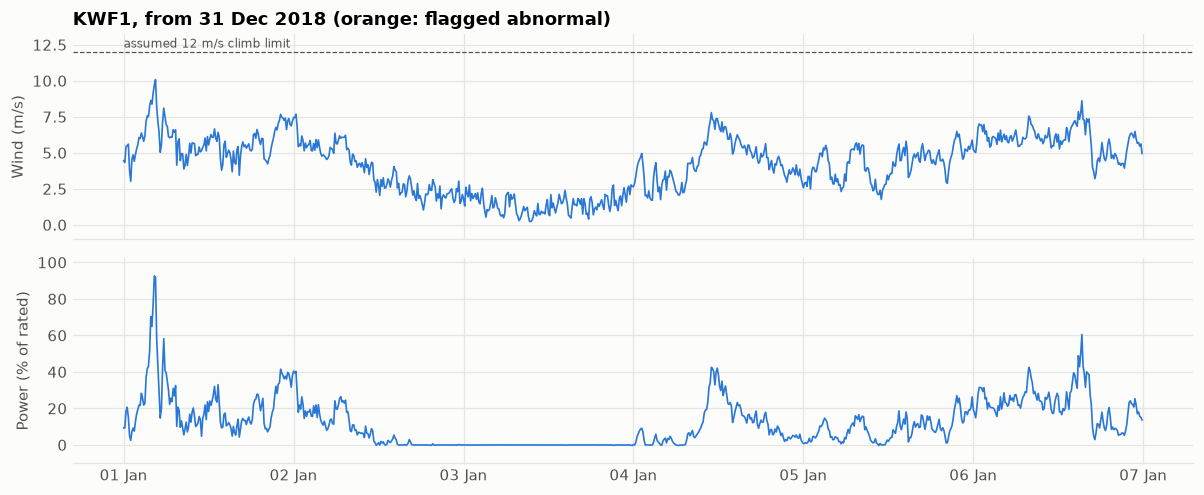

Mean wind 4.2 m/s, energy 35.7 MWh, healthy 98%, 1 stops


,start,hours,Message,IEC category
0,2019-01-01 11:03:12,0.04,Battery test,Technical Standby


In [20]:
t = day_cost.idxmax() - pd.Timedelta(days=3)
show_week("KWF1", t.strftime("%Y-%m-%d"))
t = day_cost.idxmin() - pd.Timedelta(days=3)
show_week("KWF1", t.strftime("%Y-%m-%d"))

**The longest stop of the year:**

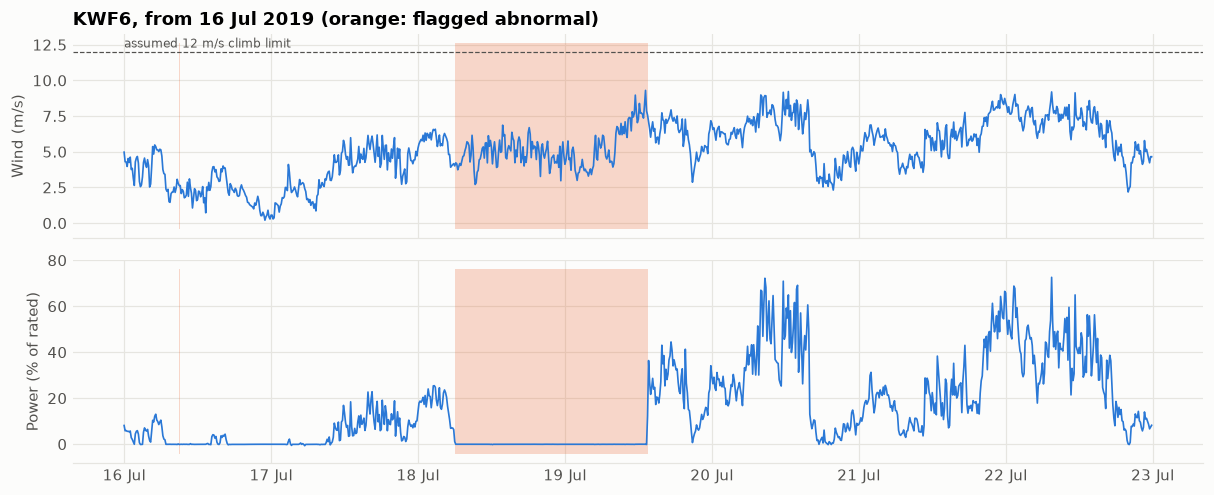

Mean wind 5.1 m/s, energy 51.5 MWh, healthy 79%, 3 stops


,start,hours,Message,IEC category
54349,2019-07-16 09:04:07,0.20,Cable autounwind,Technical Standby
54453,2019-07-18 06:01:58,31.38,Batt. undervoltage/overvoltage,Forced outage
54578,2019-07-19 13:25:57,0.12,Battery test,Technical Standby


In [21]:
s = events[events.Status == "Stop"].sort_values("hours", ascending=False).iloc[0]
show_week(s.turbine, (s.start - pd.Timedelta(days=2)).strftime("%Y-%m-%d"), days=7)

**Random rows.** Change `seed` for a different set, or use `where` to filter:

In [22]:
rows(8, seed=11)

315,360 rows match


,ts,turbine,power_kw,frac,wind_ms,wind_std_ms,wind_dir_deg,nacelle_deg,pitch_deg,rotor_rpm,temp_c,gear_oil_c,healthy
272937,2019-03-12 09:30:00,KWF6,2062.05,1.01,13.72,2.00,201.20,208.75,9.69,15.19,9.35,52.49,True
225562,2019-04-17 09:40:00,KWF5,201.31,0.10,4.64,0.69,24.27,28.27,0.05,9.00,11.75,50.92,True
69040,2019-04-25 10:40:00,KWF2,569.52,0.28,6.46,0.84,172.53,163.78,0.00,12.06,12.60,58.52,True
285010,2019-06-04 05:40:00,KWF6,128.11,0.06,4.31,0.68,172.62,174.73,0.39,9.00,9.92,56.95,True
295492,2019-08-16 00:40:00,KWF6,84.45,0.04,3.88,0.45,211.45,214.24,1.06,9.47,14.25,56.52,True
100293,2019-11-28 11:30:00,KWF2,327.14,0.16,5.48,0.96,332.65,326.22,0.00,10.21,9.56,58.02,True
48148,2019-12-01 08:40:00,KWF1,356.02,0.17,5.67,0.44,10.28,10.93,0.00,10.38,3.22,57.05,True
315218,2019-12-31 00:20:00,KWF6,256.32,0.13,5.17,0.56,334.54,336.07,0.00,9.54,9.01,56.66,True


In [23]:
rows(6, seed=2, where="wind_ms > 18")

183 rows match


,ts,turbine,power_kw,frac,wind_ms,wind_std_ms,wind_dir_deg,nacelle_deg,pitch_deg,rotor_rpm,temp_c,gear_oil_c,healthy
5361,2019-02-07 05:30:00,KWF1,2081.03,1.02,18.05,1.81,242.42,244.72,16.71,15.32,6.06,51.90,True
8912,2019-03-03 21:20:00,KWF1,2017.24,0.98,19.69,3.60,226.52,221.33,18.68,15.02,9.49,53.86,True
219156,2019-03-03 22:00:00,KWF5,-3.17,-0.00,20.63,3.60,222.16,232.42,89.99,0.26,7.98,46.51,False
168398,2019-03-16 10:20:00,KWF4,2052.23,1.00,18.14,2.47,238.34,228.95,16.64,15.25,10.86,50.46,True
115848,2019-03-16 12:00:00,KWF3,2060.00,1.00,18.24,2.00,227.99,229.95,17.18,15.21,11.00,53.51,True
10732,2019-03-16 12:40:00,KWF1,2067.76,1.01,19.79,2.37,230.49,229.95,18.77,15.25,11.79,54.45,True


In [24]:
rows(6, seed=3, where="temp_c < 0 and wind_ms > 7")

320 rows match


,ts,turbine,power_kw,frac,wind_ms,wind_std_ms,wind_dir_deg,nacelle_deg,pitch_deg,rotor_rpm,temp_c,gear_oil_c,healthy
109591,2019-02-01 01:10:00,KWF3,1400.69,0.68,8.70,1.12,57.41,56.09,0.01,14.89,-0.20,49.29,True
109599,2019-02-01 02:30:00,KWF3,1123.16,0.55,8.02,1.04,50.33,45.12,0.23,14.45,-0.48,48.15,True
214727,2019-02-01 03:50:00,KWF5,1230.35,0.60,8.17,1.23,46.54,46.93,0.00,14.63,-0.46,53.19,True
214729,2019-02-01 04:10:00,KWF5,1184.50,0.58,8.35,1.20,52.52,46.93,0.00,14.58,-0.45,49.21,True
109764,2019-02-02 06:00:00,KWF3,1415.07,0.69,8.61,0.96,337.67,340.36,0.15,14.94,-0.30,48.62,True
214892,2019-02-02 07:20:00,KWF5,1603.78,0.78,9.05,0.68,328.36,331.20,0.00,15.16,-0.57,48.13,True


**Suspects:** rows counted as healthy that still produce far below normal:

In [25]:
suspects(8)

178 of 97,184 healthy rows at 7+ m/s are over 15% of rated below typical (0.18%)


,ts,turbine,power_kw,frac,typical,wind_ms,wind_std_ms,pitch_deg,rotor_rpm,temp_c
267600,2019-02-03 08:00:00,KWF6,708.07,0.35,0.52,7.77,0.58,0.00,12.72,1.98
114723,2019-03-08 16:30:00,KWF3,1095.34,0.53,0.71,8.78,0.87,0.02,14.48,7.64
180595,2019-06-09 03:10:00,KWF4,940.65,0.46,0.61,8.36,0.62,0.00,14.12,9.79
134012,2019-07-20 15:20:00,KWF3,1309.76,0.64,0.80,9.33,1.47,0.80,14.54,20.73
187227,2019-07-25 04:30:00,KWF4,960.59,0.47,0.71,8.91,0.53,0.00,14.44,24.64
31205,2019-08-05 16:50:00,KWF1,1371.64,0.67,0.88,9.77,1.78,1.36,14.74,21.98
37881,2019-09-21 01:30:00,KWF1,938.66,0.46,0.61,8.36,0.78,0.00,14.07,12.85
200427,2019-10-24 20:30:00,KWF4,944.24,0.46,0.61,8.32,0.49,0.00,14.16,10.92


In [26]:
g = df[df.healthy & (df.wind_ms >= 7)].assign(typical=lambda x: ((x.wind_ms * 2).round() / 2).map(typical))
g["short"] = g.typical - g.frac > 0.15
print("Share of suspect rows per turbine:", (g.groupby("turbine").short.mean() * 100).round(2).to_dict())
print("Share by temperature band:", (g.groupby(pd.cut(g.temp_c, [-20, 0, 3, 10, 40]), observed=True).short.mean() * 100).round(2).to_dict())
top = g[g.short].assign(day=lambda x: x.ts.dt.floor("D")).groupby(["turbine", "day"]).size().sort_values(ascending=False).head(6)
print("Days with the most suspect rows:"); print(top.to_string())
print("\nDistribution of shortfall on healthy rows at 7+ m/s (points of rated):", ((g.typical - g.frac) * 100).describe(percentiles=[.5, .9, .99, .999]).round(1).to_dict())
ab = df[~df.healthy & (df.wind_ms >= 7)]
print(f"Abnormal rows at 7+ m/s: {len(ab):,}; {(ab.frac < 0.02).mean():.0%} of them produce under 2% of rated, so the filter is catching real stops")
wxh = w.relative_humidity_2m.reindex(df.ts.dt.floor("h")).to_numpy()
cold = df.temp_c.between(-3, 1).to_numpy() & (wxh >= 85)
print(f"Icing conditions (-3 to +1 C, humidity 85%+): {cold.mean():.1%} of rows, on {df.ts[cold].dt.floor('D').nunique()} days, months {sorted(df.ts[cold].dt.month.unique().tolist())}")

Share of suspect rows per turbine: {'KWF1': 0.14, 'KWF2': 0.1, 'KWF3': 0.36, 'KWF4': 0.24, 'KWF5': 0.12, 'KWF6': 0.14}
Share by temperature band: {Interval(-20, 0, closed='right'): 0.0, Interval(0, 3, closed='right'): 0.3, Interval(3, 10, closed='right'): 0.1, Interval(10, 40, closed='right'): 0.27}
Days with the most suspect rows:
turbine  day       
KWF1     2019-05-04    5
KWF3     2019-06-02    3
KWF5     2019-05-04    3
KWF4     2019-03-29    2
KWF3     2019-02-03    2
         2019-07-21    2

Distribution of shortfall on healthy rows at 7+ m/s (points of rated): {'count': 97184.0, 'mean': -0.2, 'std': 4.9, 'min': -41.3, '50%': -0.2, '90%': 6.0, '99%': 11.5, '99.9%': 16.0, 'max': 39.4}


Abnormal rows at 7+ m/s: 731; 74% of them produce under 2% of rated, so the filter is catching real stops
Icing conditions (-3 to +1 C, humidity 85%+): 0.7% of rows, on 19 days, months [1, 2, 4, 11, 12]


In [27]:
# The longest warning of the year: a choked gear oil filter. Does it show up in the data?
ev = events[events.Message == "Oil filter gear choked"][["turbine", "start", "end", "hours"]].round(0); display(ev)
for x in ev.itertuples():
    on = (df.turbine == x.turbine) & (df.ts >= x.start) & (df.ts < x.end) & df.healthy & df.frac.between(0.2, 0.9)
    ref = (df.turbine == x.turbine) & ~((df.ts >= x.start) & (df.ts < x.end)) & df.healthy & df.frac.between(0.2, 0.9)
    print(f"{x.turbine}: gear oil {df.gear_oil_c[on].mean():.1f} C vs. {df.gear_oil_c[ref].mean():.1f} C otherwise; power vs. typical for the wind {(df.frac[on] - ((df.wind_ms[on] * 2).round() / 2).map(typical)).mean() * 100:+.1f} vs. {(df.frac[ref] - ((df.wind_ms[ref] * 2).round() / 2).map(typical)).mean() * 100:+.1f} points")

,turbine,start,end,hours
573,KWF1,2019-02-24 16:46:28,2019-04-04 12:35:45,932.0
1435,KWF1,2019-04-09 10:09:03,2019-05-21 10:06:24,1008.0
2766,KWF1,2019-05-28 20:55:45,2019-05-30 07:34:04,35.0


KWF1: gear oil 52.8 C vs. 53.9 C otherwise; power vs. typical for the wind +1.0 vs. +0.4 points
KWF1: gear oil 54.1 C vs. 53.8 C otherwise; power vs. typical for the wind +0.5 vs. +0.4 points


KWF1: gear oil 53.6 C vs. 53.8 C otherwise; power vs. typical for the wind +0.0 vs. +0.4 points


**What this shows**

- **Few natural anomalies:** 178 of 97,184 healthy rows at 7+ m/s (0.18%) are more than 15 points of rated below typical. They're scattered, with at most 5 on any turbine-day. 4 May appears on several turbines, so it's worth a look with `show_week`.
- **For M2:** there's no real multi-day underperformance to train or test on in this year, so injected faults are needed. A small slow fault could still be hiding, so this isn't proof that none exist.
- **Icing is rare here:** icing conditions cover 0.7% of rows on 19 days. Few real windows exist to inject it into, and Dobrogea's winters differ from the UK's.